# Final results: cloud vs federated vs on-device

This notebook reads the aggregate result tables in `results/rees46/` and `results/benchmarks/` and draws the key
figures of [`docs/results.md`](../docs/results.md). It needs no data download and no GPU: every number comes from the
committed CSV files, which hold one row per arm, contrast or dataset and no per-user values.

Confirmatory numbers come from the single registered test look. Numbers marked *exploratory* were produced after
that look and are shown beside the confirmatory ones, never instead of them.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REES46, BENCH = ROOT / "results" / "rees46", ROOT / "results" / "benchmarks"

# Light chart palette: fixed categorical order, recessive axes, text in ink colours (never the series colour).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 72, "savefig.dpi": 72, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "legend.frameon": False,
})

## 1. How much quality is retained on REES46 (confirmatory)

Retention `R(A / B) = 100 x A / B` in client-macro MRR@20 on the test split, with 95 % paired-bootstrap intervals.
`K20b` (with `K21`) is the primary result: the deployable warm federated system against its matched central model.

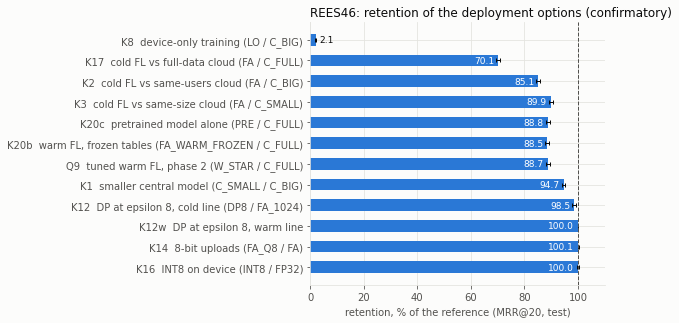

  id                   contrast     point  ci95_low  ci95_high
K20b R(FA_WARM_FROZEN / C_FULL) 88.490000 87.730000  89.180000
 K21       FA_WARM_FROZEN − PRE -0.000508 -0.000933  -0.000037


In [ ]:
k = pd.read_csv(REES46 / "confirmatory_phase1_contrasts.csv")
q = pd.read_csv(REES46 / "confirmatory_phase2_contrasts.csv")
labels = {
    "K8": "device-only training (LO / C_BIG)",
    "K17": "cold FL vs full-data cloud (FA / C_FULL)",
    "K2": "cold FL vs same-users cloud (FA / C_BIG)",
    "K3": "cold FL vs same-size cloud (FA / C_SMALL)",
    "K20c": "pretrained model alone (PRE / C_FULL)",
    "K20b": "warm FL, frozen tables (FA_WARM_FROZEN / C_FULL)",
    "Q9": "tuned warm FL, phase 2 (W_STAR / C_FULL)",
    "K1": "smaller central model (C_SMALL / C_BIG)",
    "K12": "DP at epsilon 8, cold line (DP8 / FA_1024)",
    "K12w": "DP at epsilon 8, warm line",
    "K14": "8-bit uploads (FA_Q8 / FA)",
    "K16": "INT8 on device (INT8 / FP32)",
}
rows = pd.concat([k, q])
rows = rows[rows["id"].isin(labels)].set_index("id").loc[list(labels)]
fig, ax = plt.subplots(figsize=(8.6, 4.6))
y = range(len(rows))
ax.barh(y, rows["point"], height=0.55, color=BLUE)
ax.errorbar(rows["point"], y, xerr=[rows["point"] - rows["ci95_low"], rows["ci95_high"] - rows["point"]],
            fmt="none", ecolor=INK, elinewidth=1, capsize=2)
ax.axvline(100, color=INK_2, linewidth=1, linestyle="--")
ax.set_yticks(list(y), [f"{i}  {labels[i]}" for i in rows.index])
ax.invert_yaxis()
for yi, v in zip(y, rows["point"]):
    ax.text(min(v, 100) + 1.5 if v < 60 else v - 1.5, yi, f"{v:.1f}", va="center",
            ha="left" if v < 60 else "right", color="white" if v >= 60 else INK, fontsize=9)
ax.set_xlim(0, 110)
ax.set_xlabel("retention, % of the reference (MRR@20, test)")
ax.set_title("REES46: retention of the deployment options (confirmatory)", loc="left", color=INK)
plt.tight_layout()
plt.show()
print(k.loc[k["id"].isin(["K20b", "K21"]), ["id", "contrast", "point", "ci95_low", "ci95_high"]].to_string(index=False))

The warm federated system keeps 88.5 % of `C_FULL`, but `K21` shows it is slightly *below* the pretrained model it
started from: on REES46 federated training adds nothing over a strong server pretrain. Phase 2's tuned recipe reads
as equivalent to the pretrain (`Q1`).

## 2. Federated vs central on the public benchmarks

NDCG@10 of the best federated arm as a percentage of the central model `C_FULL`, on the test split. *Registered*
is the confirmatory recipe (FedAdam `tau = 1e-3`); *tau-fixed* is the exploratory recipe scored after the confirmatory
look; `C_SMALL` is the central model at the device size.

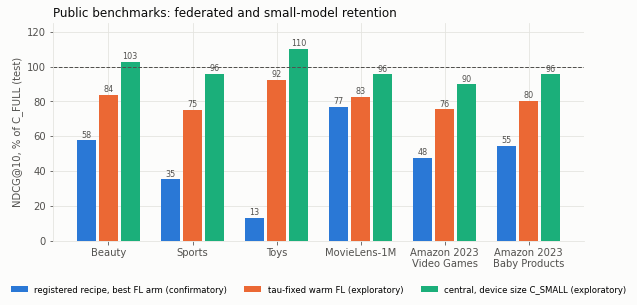

In [ ]:
a = pd.read_csv(BENCH / "confirmatory_track_a.csv")
x = pd.read_csv(BENCH / "exploratory_fixed_fl_test.csv")
fl = a[a["arm"].isin(["FA", "FA_WARM", "FA_WARM_FROZEN"])]
registered = fl.groupby("dataset", sort=False)["ndcg@10_pct_of_c_full"].max()
x = x.set_index("dataset").loc[registered.index]
series = [("registered recipe, best FL arm (confirmatory)", registered.values, BLUE),
          ("tau-fixed warm FL (exploratory)", x["fa_warm_taufix_pct"].values, ORANGE),
          ("central, device size C_SMALL (exploratory)", x["c_small_pct"].values, AQUA)]
names = [d.replace("Amazon 2023 ", "AMZ23\n").replace("Amazon ", "").replace("AMZ23", "Amazon 2023") for d in registered.index]
fig, ax = plt.subplots(figsize=(9.2, 4.4))
w = 0.26
for i, (lab, vals, col) in enumerate(series):
    pos = [j + (i - 1) * w for j in range(len(names))]
    ax.bar(pos, vals, width=w - 0.03, color=col, label=lab)
    for p, v in zip(pos, vals):
        ax.text(p, v + 1.5, f"{v:.0f}", ha="center", fontsize=8, color=INK_2)
ax.axhline(100, color=INK_2, linewidth=1, linestyle="--")
ax.set_xticks(range(len(names)), names)
ax.set_ylim(0, 125)
ax.set_ylabel("NDCG@10, % of C_FULL (test)")
ax.set_title("Public benchmarks: federated and small-model retention", loc="left", color=INK)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8.5)
plt.tight_layout()
plt.show()

With the registered recipe the federated runs barely trained (13-77 %). With `tau = 1e-6` and a larger budget, the
warm federated arm keeps 75-92 %, while the smaller central model keeps 90-110 %: the remaining gap is the cost of
federation, not of model size.

## 3. Privacy: leakage once federated training learns, and what DP costs

User-level membership inference (calibrated AUC; 0.5 is chance, the material-leakage threshold is a CI lower bound
above 0.55) against the utility kept by DP-FedAvg at epsilon 8, relative to the non-private run (validation MRR@20).
Both lines are exploratory re-runs with `tau = 1e-6`.

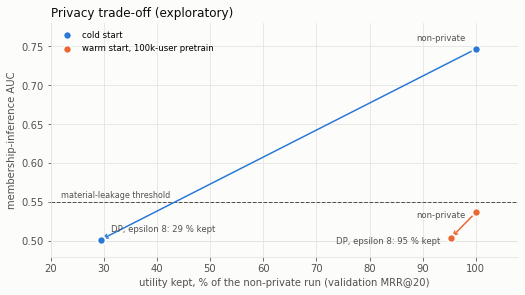

                                                                 audit     auc  auc_ci95_low  auc_ci95_high              verdict
model                                                                                                                           
FA_WARM_FROZEN                                     confirmatory models  0.5036        0.4957         0.5112  no material leakage
PRE_FT_CENTRAL                                     confirmatory models  0.6255        0.6176         0.6332     material leakage
W_STAR                                             confirmatory models  0.4971        0.4893         0.5053  no material leakage
W_STAR_DP1                                         confirmatory models  0.4973        0.4893         0.5053                 pass
W_STAR_DP8                                         confirmatory models  0.4972        0.4893         0.5053                 pass
PRE                                                confirmatory models  0.5000        0.5000     

In [ ]:
mia = pd.read_csv(REES46 / "privacy_membership_inference.csv").set_index("model")
dp = pd.read_csv(REES46 / "privacy_dp_cost.csv")
kept = dp[dp["source"] == "exploratory validation"].set_index("comparison")["retention_pct_or_ci_low"]
lines = [("cold start", "FA_COLD_TAUFIX", "FA_COLD_TAUFIX_DP8 vs FA_COLD_TAUFIX", BLUE),
         ("warm start, 100k-user pretrain", "FA_WARM_PB100K_TAUFIX", "FA_WARM_PB100K_TAUFIX_DP8 vs FA_WARM_PB100K_TAUFIX", ORANGE)]
fig, ax = plt.subplots(figsize=(7.4, 4.2))
for lab, model, key, col in lines:
    pts = [(100.0, mia.loc[model, "auc"]), (float(kept[key]), mia.loc[model + "_DP8", "auc"])]
    ax.annotate("", xy=pts[1], xytext=pts[0], arrowprops=dict(arrowstyle="->", color=col, lw=1.5))
    ax.scatter(*zip(*pts), s=70, color=col, edgecolor=SURFACE, linewidth=2, zorder=3, label=lab)
    cold = model.startswith("FA_COLD")
    ax.text(pts[0][0] - 2, pts[0][1] + (0.008 if cold else -0.004), "non-private", ha="right", va="center" if not cold else "bottom",
            fontsize=8.5, color=INK_2)
    ax.text(pts[1][0] + (2 if cold else -2), pts[1][1] + (0.008 if cold else -0.004), f"DP, epsilon 8: {pts[1][0]:.0f} % kept",
            ha="left" if cold else "right", va="bottom" if cold else "center", fontsize=8.5, color=INK_2)
ax.axhline(0.55, color=INK_2, linewidth=1, linestyle="--")
ax.text(22, 0.556, "material-leakage threshold", fontsize=8, color=INK_2)
ax.axhline(0.5, color=GRID, linewidth=1)
ax.set_xlim(20, 108)
ax.set_ylim(0.48, 0.78)
ax.set_xlabel("utility kept, % of the non-private run (validation MRR@20)")
ax.set_ylabel("membership-inference AUC")
ax.set_title("Privacy trade-off (exploratory)", loc="left", color=INK)
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()
print(mia[["audit", "auc", "auc_ci95_low", "auc_ci95_high", "verdict"]].to_string())

The confirmatory federated models do not leak because they hardly moved from the pretrained model. A federated
model that really learns from its users does leak (AUC 0.75 from a cold start). DP at epsilon 8 closes the leak; it
costs little from a pretrained start and a lot from a cold start, where most of the cost comes from the shorter,
clipped DP schedule rather than from the noise (on the confirmatory test, noise alone cost 0-6 %).

## 4. Device feasibility

In-browser inference of the phase-2 federated model with ONNX Runtime Web (latency, cold start and size only).

In [ ]:
dev = pd.read_csv(REES46 / "device_latency.csv")
dev["device"] = dev["device"].str.split(" \\(").str[0]
print(dev.pivot_table(index=["device", "backend"], columns="precision",
                      values=["warm_p50_ms", "cold_start_ms_median"]).round(1).to_string())
print()
print(dev.groupby("precision")["model_mb"].first().to_string())

                              cold_start_ms_median         warm_p50_ms     
precision                                     fp32    int8        fp32 int8
device     backend                                                         
laptop     wasm, 1 thread                    915.0   670.0         5.1  3.5
           wasm, multi-thread                895.0   695.0         2.2  1.7
phone      wasm, 1 thread                   5168.0  2573.0         2.8  3.7
           wasm, multi-thread               4863.0  2495.0         2.2  2.4
server CPU wasm, 1 thread                   1283.0  1017.0         4.6  4.3
           wasm, multi-thread               1332.0  1089.0         2.7  3.0

precision
fp32    82.9
int8    21.2
